# 03 · Signatures — embryonic module geography (Zhang et al. 2019)

Score Gast/pSom/Crest on the rooted manifold and read **Gate 2** geography. This is the
**non-branching** case: the module scores sit at control-pool baseline (weak absolute expression).
The **Gast->Crest** axis is spatially organized and confound-independent (Gast marks the
developmental origin, Crest an inverse terminal gradient, both surviving regression against
transformation / interferon / proliferation). **pSom is the exception** — it is substantially
proliferation-associated here (see the confound table below), so it is not claimed as an
independent axis. The non-branching Gate-2 criteria (Gast/pSom overlap or mild cross-repression +
an inverse terminal Crest gradient) do not require pSom confound-independence, so this remains a
clean Gate 2 = GO. Deliverable panels show the **RAW** per-cell scores (smoothing aids analysis
only). Gate 3 = NA. Deliverables: `{Gast,pSom,Crest}_signature.pdf` + colorbars, `signatures.h5ad`.

In [1]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, matplotlib.pyplot as plt
from scipy.stats import spearmanr
from numpy.linalg import lstsq
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load the rooted manifold and confirm module gene recovery

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation', 'pSom':'Somitogenesis', 'Crest':'Neural Crest'}
print('cells:', adata.shape[0], '| scores present:', [m for m in modules if m in adata.obs])
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.dropna().drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')

cells: 5645 | scores present: ['Gast', 'pSom', 'Crest']
Gast: 57/81 genes present
pSom: 60/98 genes present
Crest: 81/104 genes present


### Gate 2 — module geography, confound control, and the Crest-arm flag
Global module means give the Linear-split class; smoothed spatial correlations give the axis
structure; pseudotime gradients confirm the terminal ordering. Because the absolute scores are
weak, we **confound-control**: regress each module against progression status + an interferon/MHC
program + proliferation and check whether the pseudotime gradient survives. **Gast** and **Crest**
survive (little confound variance explained; gradients essentially unchanged) — the Gast->Crest
developmental axis is not merely the FL->DLBCL transformation or the cycling split. **pSom does
not**: ~63% of its variance is confound-explained and its high-decile is majority-cycling, so pSom
is substantially proliferation-confounded and is reported as such rather than as an independent
program. This does not affect the call: the non-branching Gate-2 criteria do not require pSom
confound-independence. The **flag** check: Crest enriches the Gast end only if `Crest_sm-Gast_sm`
> 0 while `Crest_sm-pSom_sm` < 0. Here Crest opposes *both*, so there is no inversion.

In [4]:
print('global module means (Linear split metric):',
      adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
rGp = np.corrcoef(adata.obs['Gast_sm'], adata.obs['pSom_sm'])[0,1]
rCG = np.corrcoef(adata.obs['Crest_sm'], adata.obs['Gast_sm'])[0,1]
rCp = np.corrcoef(adata.obs['Crest_sm'], adata.obs['pSom_sm'])[0,1]
print('smoothed spatial correlations (geography):')
print(f'  Gast_sm vs pSom_sm: r = {rGp:+.2f}   (mild cross-repression, no co-expression hub)')
print(f'  Crest_sm vs Gast_sm: r = {rCG:+.2f}')
print(f'  Crest_sm vs pSom_sm: r = {rCp:+.2f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
# confound control
prog_map = {'primary':0,'progressed':1,'transformed (DLBCL)':2}
prog_n = adata.obs['progression_status'].map(prog_map).astype(float).values
ifn = [g for g in ['STAT1','IRF1','GBP1','ISG15','IFI6','HLA-DRA','HLA-DRB1','CD74','B2M','HLA-A','IFI44L','MX1','IFIT3'] if g in adata.var_names]
sc.tl.score_genes(adata, ifn, score_name='ifn_score', random_state=SEED)
Xc = np.column_stack([np.ones(adata.n_obs), prog_n, adata.obs['ifn_score'].values, adata.obs['prolif_score'].values])
print('confound control (regress out progression + interferon/MHC + proliferation):')
for m in ['Gast_sm','pSom_sm','Crest_sm']:
    y = adata.obs[m].values; beta,_,_,_ = lstsq(Xc, y, rcond=None); resid = y - Xc@beta
    r2 = 1 - np.var(resid)/np.var(y)
    rb,_ = spearmanr(tn, y); ra,_ = spearmanr(tn, resid)
    print(f'  {m}: R2 confound = {r2:.2f}; rho(t) before={rb:+.2f} after={ra:+.2f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if high)')
# honest pSom confound check: is the pSom-high pole a proliferation pocket?
psom_hi = adata.obs['pSom_sm'] >= adata.obs['pSom_sm'].quantile(0.9)
print(f'pSom-high decile: cycling fraction = {adata.obs.loc[psom_hi.values,"cycling"].mean():.2f} '
      f'(baseline {adata.obs["cycling"].mean():.2f}) -> pSom substantially proliferation-confounded')
flag = (rCG > 0) and (rCp < 0)
print(f'Crest-enriches-Gast-arm flag: {flag} (Crest opposes both Gast and pSom -> no inversion)')
print('Gate 2: organized embryonic gradient (Gast origin -> Crest terminal, mild Gast/pSom '
      'cross-repression); Gast & Crest confound-independent, pSom proliferation-confounded '
      '(not required for the non-branching criteria) -> GO (non-branching)')
print('Gate 3: no bifurcation -> NA')

global module means (Linear split metric): {'Gast': 0.0117, 'pSom': 0.0062, 'Crest': 0.0092}
smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.18   (mild cross-repression, no co-expression hub)
  Crest_sm vs Gast_sm: r = -0.54
  Crest_sm vs pSom_sm: r = -0.60
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.510
  pSom_sm: rho = +0.093
  Crest_sm: rho = +0.324
confound control (regress out progression + interferon/MHC + proliferation):
  Gast_sm: R2 confound = 0.07; rho(t) before=-0.51 after=-0.46
  pSom_sm: R2 confound = 0.63; rho(t) before=+0.09 after=+0.08
  Crest_sm: R2 confound = 0.16; rho(t) before=+0.32 after=+0.38
Neural-crest-high decile mean pseudotime = 0.56 (terminal if high)
pSom-high decile: cycling fraction = 0.54 (baseline 0.14) -> pSom substantially proliferation-confounded
Crest-enriches-Gast-arm flag: False (Crest opposes both Gast and pSom -> no inversion)
Gate 2: organized embryonic gradient (Gast origin -> Crest termin

### Signature maps (whole panel, house linear layout)
Raw per-cell scores in the house linear layout (root at left), one quick 3-panel view before the
individual deliverable panels.

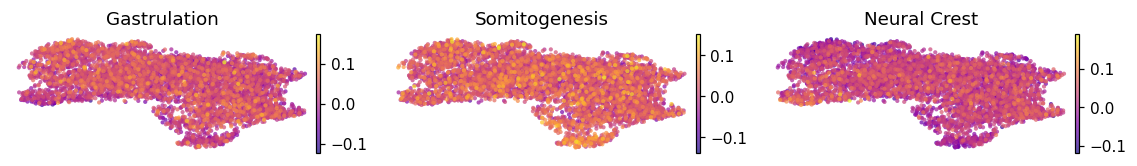

In [5]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, axes = plt.subplots(1, 3, figsize=(10.5,1.6))
for ax,(m,title) in zip(axes, modules.items()):
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc='right',
               frameon=False, show=False, ax=ax, title=title)
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
fig.tight_layout()

### Deliverable panels + colorbars (RAW per-cell scores)
One `(3.5,1.5)` panel per module in the shared linear orientation (root at left), plus an external
colorbar each, matching the reference deliverable format. Raw (not smoothed) scores are shown so 10x
dropout is visible.

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


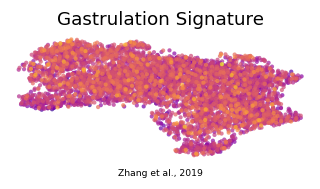

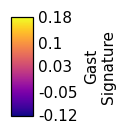

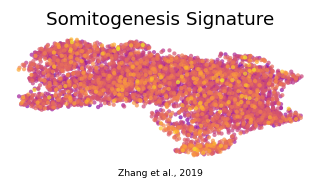

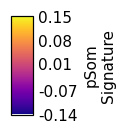

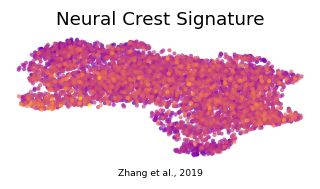

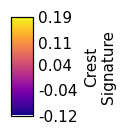

In [6]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Zhang et al., 2019', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')

In [7]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (5645, 14715)
